# Chapter 1 · Counting and axioms

*Book 3 · Probability · Shelf I*

**Builds on:** arithmetic, and sets.
**You will:** state what a probability is, count outcomes exactly with permutations and
combinations, and check every count by simulation -- the habit the rest of the book relies on.

A probability assigns every **event** (a set of outcomes) a number in [0, 1] such that the whole
sample space gets 1 and disjoint events add up (Kolmogorov's axioms). Everything else -- complements,
unions, conditional probability -- follows from those three rules. When all outcomes are equally
likely, probability is counting: favourable outcomes over all outcomes.

In [1]:
from math import comb, factorial, perm

import matplotlib.pyplot as plt
import numpy as np

from ds_toolbox import viz

viz.use_style()
rng = np.random.default_rng(1)

## Order matters, or it does not

Arranging $k$ of $n$ distinct things in order: $n!/(n-k)!$ ways (**permutations**). Choosing $k$
of $n$ without regard to order: $\binom{n}{k} = \frac{n!}{k!(n-k)!}$ (**combinations**) -- the
permutations divided by the $k!$ orders of each choice.

In [2]:
print("podium of 3 from 10 runners (order matters):", perm(10, 3))
print("team of 3 from 10 (order does not):         ", comb(10, 3), "=", perm(10, 3), "/", factorial(3))

podium of 3 from 10 runners (order matters): 720
team of 3 from 10 (order does not):          120 = 720 / 6


## The Swiss lottery

Swiss Lotto draws 6 numbers from 1-42 and a lucky number from 1-6. The jackpot needs all seven.

In [3]:
p_jackpot = 1 / (comb(42, 6) * 6)
print(f"P(jackpot) = 1 / {comb(42, 6) * 6:,} = {p_jackpot:.2e}")
p_three = comb(6, 3) * comb(36, 3) / comb(42, 6)
print(f"P(exactly 3 of the 6 main numbers) = {p_three:.4f}")

draws = np.array([rng.choice(42, 6, replace=False) for _ in range(200_000)])
ticket = np.arange(6)
matches = np.isin(draws, ticket).sum(axis=1)
print(f"simulated, 200 000 draws: P(exactly 3) = {(matches == 3).mean():.4f}")

P(jackpot) = 1 / 31,474,716 = 3.18e-08
P(exactly 3 of the 6 main numbers) = 0.0272


simulated, 200 000 draws: P(exactly 3) = 0.0273


The simulation agrees with the count for exactly three matches. For the jackpot it cannot: at one in
31 million, 200 000 draws would almost never see it. Rare events need either a count or a
smarter simulation -- chapter 6.

## The birthday problem

How many people in a room before two share a birthday more likely than not? Count the complement:
the chance that $n$ birthdays are all different is $\frac{365}{365} \cdot \frac{364}{365} \cdots
\frac{365 - n + 1}{365}$.

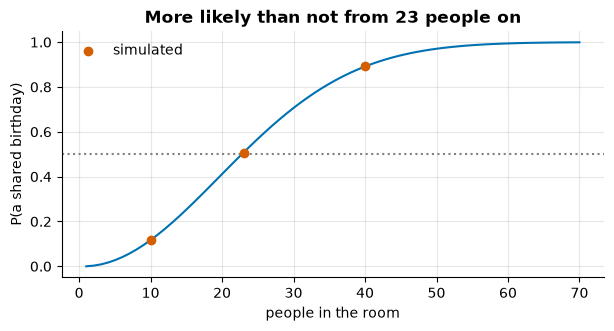

In [4]:
n = np.arange(1, 71)
p_shared = 1 - np.cumprod((365 - n + 1) / 365)
first = int(n[np.argmax(p_shared > 0.5)])
sim = [np.mean([len(set(rng.integers(0, 365, k))) < k for _ in range(4000)]) for k in (10, 23, 40)]
plt.figure(figsize=(7, 3.2))
plt.plot(n, p_shared)
plt.scatter([10, 23, 40], sim, color=viz.PALETTE[3], zorder=3, label="simulated")
plt.axhline(0.5, color="0.5", ls=":")
plt.xlabel("people in the room")
plt.ylabel("P(a shared birthday)")
plt.legend()
plt.title(f"More likely than not from {first} people on");

Intuition says something near 180. The count says 23 -- because the question is about *any* pair,
and 23 people form 253 pairs.

## What to remember

- Probability is a measure on events: non-negative, total 1, additive over disjoint events.
- Count with permutations when order matters, combinations when it does not; count the complement
  when the event is "at least one".
- Check a count by simulation -- and know that simulation alone cannot see a rare event.

## Exercises

1. What is the probability of 5 main numbers and the lucky number in Swiss Lotto?
2. How many people for a 50 % chance that someone shares *your* birthday?
3. Simulate the birthday problem with realistic birthdays (more births in summer). Does 23 move?

**Next:** [Chapter 2 · Random variables](02-random-variables.ipynb)